# Lab 6 ? Neural Networks

Keras and PyTorch MLP classification on sklearn Breast Cancer, followed by LSTM/GRU forecasting on AirPassengers. All code comments are in English.

## 1. Imports and data

In [3]:
import os, random
import numpy as np, pandas as pd, matplotlib.pyplot as plt
SEED=42
os.environ["PYTHONHASHSEED"]=str(SEED); random.seed(SEED); np.random.seed(SEED)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score

tf.random.set_seed(SEED); torch.manual_seed(SEED)
print("TensorFlow",tf.__version__,"PyTorch",torch.__version__)
cancer=load_breast_cancer()
X0=cancer.data.astype("float32"); y0=cancer.target.astype("float32")
Xtr0,Xtest0,ytr0,ytest=train_test_split(X0,y0,test_size=.2,random_state=SEED,stratify=y0)
Xtrain0,Xval0,ytrain,yval=train_test_split(Xtr0,ytr0,test_size=.2,random_state=SEED,stratify=ytr0)
scaler=StandardScaler(); Xtrain=scaler.fit_transform(Xtrain0).astype("float32")
Xval=scaler.transform(Xval0).astype("float32"); Xtest=scaler.transform(Xtest0).astype("float32")
print(Xtrain.shape,Xval.shape,Xtest.shape)


TensorFlow 2.21.0 PyTorch 2.9.0+cpu
(364, 30) (91, 30) (114, 30)


## 2. Keras architecture experiments and early stopping

Validation loss selects the best epoch. Test metrics are reported only after training.

In [4]:
def build_mlp(widths=(32,16),dropout=0.,batch_norm=False):
    model=keras.Sequential([keras.Input(shape=(Xtrain.shape[1],))])
    for width in widths:
        model.add(layers.Dense(width,use_bias=not batch_norm))
        if batch_norm: model.add(layers.BatchNormalization())
        model.add(layers.ReLU())
        if dropout: model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1,activation="sigmoid"))
    model.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])
    return model

def fit_keras(widths,dropout=0.,batch_norm=False):
    keras.backend.clear_session(); tf.random.set_seed(SEED)
    m=build_mlp(widths,dropout,batch_norm)
    h=m.fit(Xtrain,ytrain,validation_data=(Xval,yval),epochs=300,batch_size=32,verbose=0,
      callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss",patience=20,min_delta=1e-4,restore_best_weights=True)])
    p=(m.predict(Xtest,verbose=0).ravel()>=.5).astype(int)
    return m,h,{"best_epoch":int(np.argmin(h.history["val_loss"])+1),"epochs_run":len(h.history["loss"]),"test_accuracy":accuracy_score(ytest,p),"test_f1":f1_score(ytest,p)}

architectures={"shallow_16":(16,),"medium_32_16":(32,16),"deep_64_32_16":(64,32,16)}
keras_runs={}; rows=[]
for name,widths in architectures.items():
    m,h,metrics=fit_keras(widths); keras_runs[name]=(m,h); rows.append({"model":name,**metrics})
pd.DataFrame(rows).sort_values("test_f1",ascending=False)


,model,best_epoch,epochs_run,test_accuracy,test_f1
0,shallow_16,72,88,0.956140,0.965035
1,medium_32_16,34,54,0.947368,0.957746
2,deep_64_32_16,14,34,0.947368,0.957746


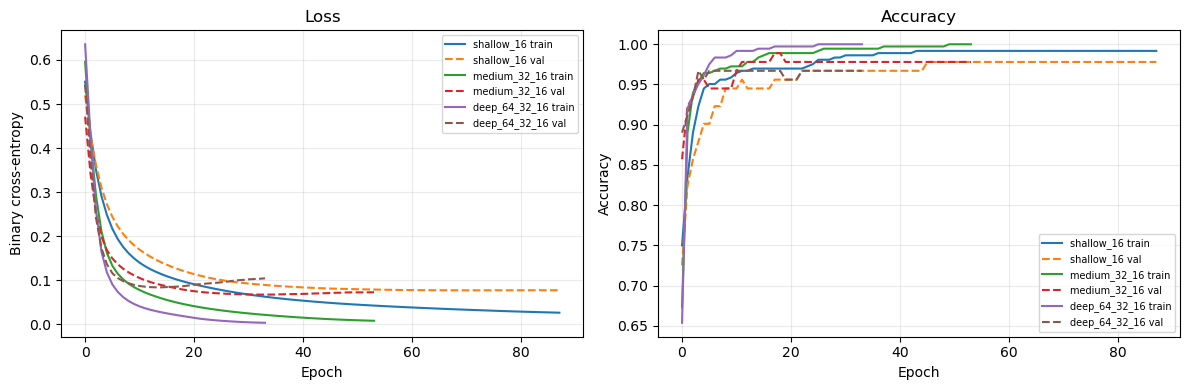

In [5]:
fig,axs=plt.subplots(1,2,figsize=(12,4))
for name,(_,h) in keras_runs.items():
    axs[0].plot(h.history["loss"],label=name+" train"); axs[0].plot(h.history["val_loss"],"--",label=name+" val")
    axs[1].plot(h.history["accuracy"],label=name+" train"); axs[1].plot(h.history["val_accuracy"],"--",label=name+" val")
axs[0].set(title="Loss",xlabel="Epoch",ylabel="Binary cross-entropy"); axs[1].set(title="Accuracy",xlabel="Epoch",ylabel="Accuracy")
for ax in axs: ax.legend(fontsize=7); ax.grid(alpha=.25)
plt.tight_layout()


## 3. Dropout and BatchNormalization

Compare regularization choices using the same medium architecture and early-stopping criteria.

In [6]:
reg_runs={}; reg_rows=[]
for name,drop,bn in [("baseline",0,False),("dropout_0.3",.3,False),("batch_norm",0,True),("dropout_and_batch_norm",.3,True)]:
    m,h,metrics=fit_keras((32,16),drop,bn); reg_runs[name]=(m,h)
    reg_rows.append({"model":name,**metrics})
pd.DataFrame(reg_rows).sort_values("test_f1",ascending=False)


,model,best_epoch,epochs_run,test_accuracy,test_f1
3,dropout_and_batch_norm,74,94,0.973684,0.979021
1,dropout_0.3,82,102,0.964912,0.972222
0,baseline,34,54,0.947368,0.957746
2,batch_norm,53,73,0.947368,0.957746


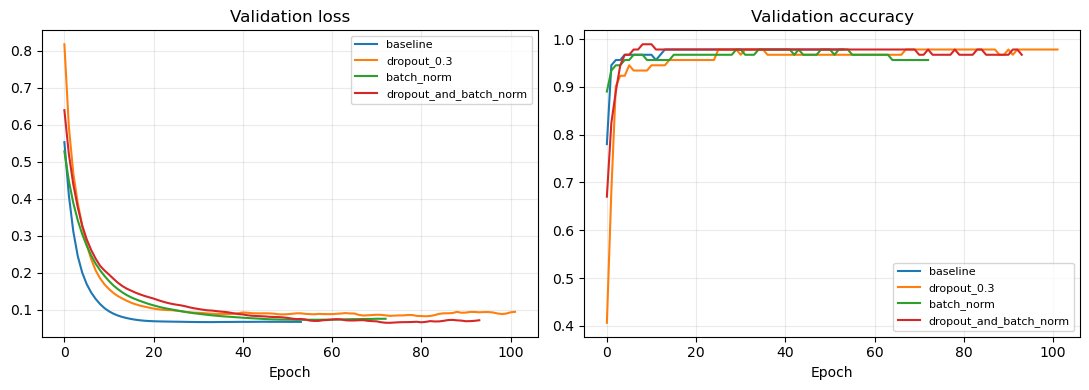

In [7]:
fig,axs=plt.subplots(1,2,figsize=(11,4))
for name,(_,h) in reg_runs.items():
    axs[0].plot(h.history["val_loss"],label=name); axs[1].plot(h.history["val_accuracy"],label=name)
axs[0].set(title="Validation loss",xlabel="Epoch"); axs[1].set(title="Validation accuracy",xlabel="Epoch")
for ax in axs: ax.legend(fontsize=8); ax.grid(alpha=.25)
plt.tight_layout()


## 4. PyTorch comparison

PyTorch uses the same split, hidden widths, optimizer, and patience-based early stopping as the Keras medium model.

In [8]:
class TorchMLP(nn.Module):
    def __init__(self,n,widths=(32,16)):
        super().__init__(); seq=[]; prev=n
        for w in widths: seq += [nn.Linear(prev,w),nn.ReLU()]; prev=w
        seq += [nn.Linear(prev,1)]; self.net=nn.Sequential(*seq)
    def forward(self,x): return self.net(x).squeeze(1)

def fit_torch(patience=20,max_epochs=300):
    torch.manual_seed(SEED); device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
    loader=DataLoader(TensorDataset(torch.tensor(Xtrain),torch.tensor(ytrain)),batch_size=32,shuffle=True)
    model=TorchMLP(Xtrain.shape[1]).to(device); opt=torch.optim.Adam(model.parameters(),lr=1e-3); loss_fn=nn.BCEWithLogitsLoss()
    xv=torch.tensor(Xval,device=device); yv=torch.tensor(yval,device=device)
    hist={k:[] for k in ["loss","val_loss","accuracy","val_accuracy"]}; best=float("inf"); best_state=None; best_epoch=0; stale=0
    for epoch in range(max_epochs):
        model.train()
        for xb,yb in loader:
            xb,yb=xb.to(device),yb.to(device); opt.zero_grad(); loss=loss_fn(model(xb),yb); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            lt=loss_fn(model(torch.tensor(Xtrain,device=device)),torch.tensor(ytrain,device=device)).item()
            lv=loss_fn(model(xv),yv).item()
            pt=(model(torch.tensor(Xtrain,device=device)).cpu().numpy()>=0).astype(int)
            pv=(model(xv).cpu().numpy()>=0).astype(int)
        hist["loss"].append(lt); hist["val_loss"].append(lv)
        hist["accuracy"].append(accuracy_score(ytrain,pt)); hist["val_accuracy"].append(accuracy_score(yval,pv))
        if lv<best-1e-4:
            best=lv; best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}; best_epoch=epoch+1; stale=0
        else:
            stale+=1
            if stale>=patience: break
    model.load_state_dict(best_state); model.eval()
    with torch.no_grad(): pred=(model(torch.tensor(Xtest,device=device)).cpu().numpy()>=0).astype(int)
    return model,hist,{"best_epoch":best_epoch,"epochs_run":len(hist["loss"]),"test_accuracy":accuracy_score(ytest,pred),"test_f1":f1_score(ytest,pred)}

torch_model,torch_history,torch_metrics=fit_torch()
keras_metrics=next(r for r in rows if r["model"]=="medium_32_16")
pd.DataFrame([{ "framework":"Keras",**keras_metrics},{"framework":"PyTorch",**torch_metrics}])


,framework,model,best_epoch,epochs_run,test_accuracy,test_f1
0,Keras,medium_32_16,34,54,0.947368,0.957746
1,PyTorch,NaN,36,56,0.956140,0.964539


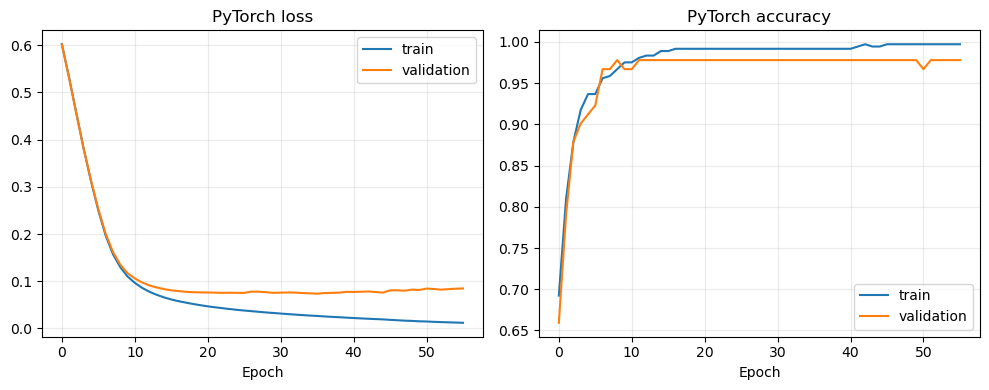

In [9]:
fig,axs=plt.subplots(1,2,figsize=(10,4))
for ax,metric in zip(axs,["loss","accuracy"]):
    ax.plot(torch_history[metric],label="train"); ax.plot(torch_history["val_"+metric],label="validation")
    ax.set(title="PyTorch "+metric,xlabel="Epoch"); ax.legend(); ax.grid(alpha=.25)
plt.tight_layout()


## 5. AirPassengers data

Read the supplied CSV when available. Otherwise, use the canonical 144 monthly observations below. The final 20% is held out chronologically for testing; the scaler is fit using only the earlier period.

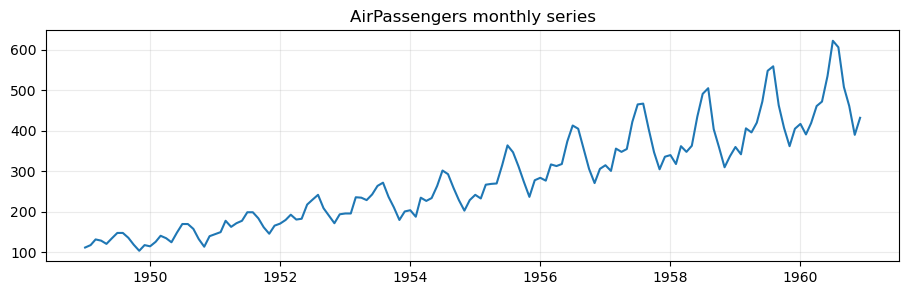

In [10]:
from pathlib import Path
csv_path=Path(r"C:\Users\Kate\Downloads\archive (1)\AirPassengers.csv")
if csv_path.exists():
    air=pd.read_csv(csv_path); passengers=air["#Passengers"].to_numpy(dtype="float32"); dates=pd.to_datetime(air["Month"])
else:
    passengers=np.array([112, 118, 132, 129, 121, 135, 148, 148, 136, 119, 104, 118, 115, 126, 141, 135, 125, 149, 170, 170, 158, 133, 114, 140, 145, 150, 178, 163, 172, 178, 199, 199, 184, 162, 146, 166, 171, 180, 193, 181, 183, 218, 230, 242, 209, 191, 172, 194, 196, 196, 236, 235, 229, 243, 264, 272, 237, 211, 180, 201, 204, 188, 235, 227, 234, 264, 302, 293, 259, 229, 203, 229, 242, 233, 267, 269, 270, 315, 364, 347, 312, 274, 237, 278, 284, 277, 317, 313, 318, 374, 413, 405, 355, 306, 271, 306, 315, 301, 356, 348, 355, 422, 465, 467, 404, 347, 305, 336, 340, 318, 362, 348, 363, 435, 491, 505, 404, 359, 310, 337, 360, 342, 406, 396, 420, 472, 548, 559, 463, 407, 362, 405, 417, 391, 419, 461, 472, 535, 622, 606, 508, 461, 390, 432],dtype="float32")
    dates=pd.date_range("1949-01",periods=len(passengers),freq="MS")
assert len(passengers)==144
plt.figure(figsize=(11,3)); plt.plot(dates,passengers); plt.title("AirPassengers monthly series"); plt.grid(alpha=.25)
test_start=int(.8*len(passengers)); air_scaler=StandardScaler().fit(passengers[:test_start,None]); values=air_scaler.transform(passengers[:,None]).ravel().astype("float32")


## 6. LSTM versus GRU; sequence length

Each model predicts one month ahead. Training and validation are ordered in time. RMSE/MAE are reported in passenger-thousands on the held-out final period.

In [11]:
def windows(seq_len,start,end):
    # Return windows whose target indices are in [start, end).
    ids=range(max(seq_len,start),end)
    return np.array([values[i-seq_len:i] for i in ids],dtype="float32")[...,None],np.array([values[i] for i in ids],dtype="float32")
def fit_forecast(kind,seq_len):
    val_start=int(test_start*.8)
    Xf,yf=windows(seq_len,seq_len,val_start); Xv,yv=windows(seq_len,val_start,test_start); Xt,yt=windows(seq_len,test_start,len(values))
    keras.backend.clear_session(); tf.random.set_seed(SEED)
    R=layers.LSTM if kind=="LSTM" else layers.GRU
    model=keras.Sequential([keras.Input((seq_len,1)),R(32),layers.Dense(1)])
    model.compile(optimizer="adam",loss="mse")
    h=model.fit(Xf,yf,validation_data=(Xv,yv),epochs=300,batch_size=16,shuffle=False,verbose=0,
       callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss",patience=25,min_delta=1e-4,restore_best_weights=True)])
    pred=model.predict(Xt,verbose=0).ravel()
    pred=air_scaler.inverse_transform(pred[:,None]).ravel(); actual=air_scaler.inverse_transform(yt[:,None]).ravel()
    return model,h,{"model":kind,"seq_len":seq_len,"best_epoch":int(np.argmin(h.history["val_loss"])+1),"test_RMSE":float(np.sqrt(np.mean((actual-pred)**2))),"test_MAE":float(np.mean(np.abs(actual-pred)))},actual,pred

forecast_runs={}; scores=[]
for kind in ["LSTM","GRU"]:
    m,h,row,actual,pred=fit_forecast(kind,12); forecast_runs[kind]=(h,actual,pred); scores.append(row)
pd.DataFrame(scores).sort_values("test_RMSE")


,model,seq_len,best_epoch,test_RMSE,test_MAE
1,GRU,12,138,63.725624,49.840546
0,LSTM,12,108,72.508064,62.344482


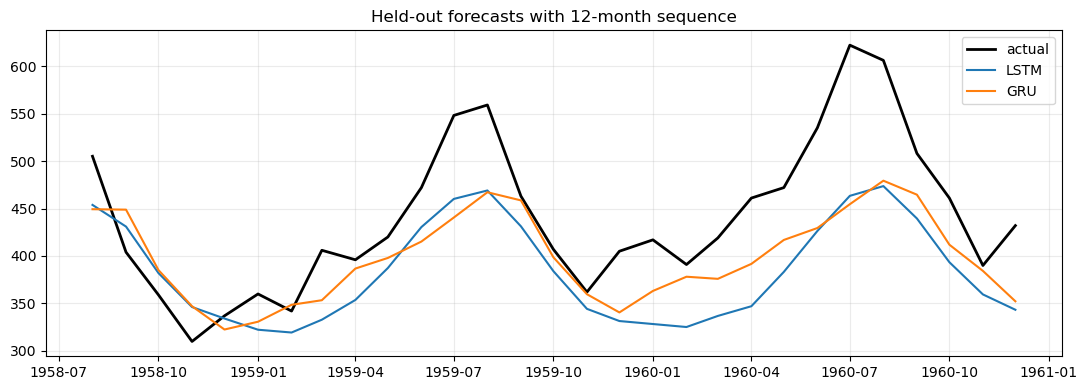

In [12]:
plt.figure(figsize=(11,4)); plt.plot(dates[test_start:],actual,color="black",lw=2,label="actual")
for kind,(_,_,pred) in forecast_runs.items(): plt.plot(dates[test_start:],pred,label=kind)
plt.title("Held-out forecasts with 12-month sequence"); plt.legend(); plt.grid(alpha=.25); plt.tight_layout()


,model,seq_len,best_epoch,test_RMSE,test_MAE
0,LSTM,3,288,49.589745,43.074596
1,GRU,3,138,49.781841,42.766029
3,GRU,6,300,59.410763,47.619343
5,GRU,12,98,61.215122,50.443417
8,LSTM,24,7,84.828270,62.607651
7,GRU,18,102,89.221046,74.526955
9,GRU,24,12,93.629105,70.236176
2,LSTM,6,16,93.881088,71.488182
6,LSTM,18,15,97.069046,72.430176
4,LSTM,12,100,123.687622,105.848969


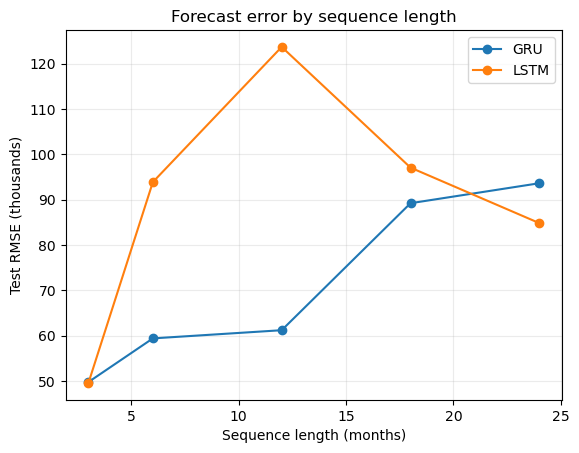

In [13]:
seq_scores=[]
for seq_len in [3,6,12,18,24]:
    for kind in ["LSTM","GRU"]:
        _,_,row,_,_=fit_forecast(kind,seq_len); seq_scores.append(row)
seq_table=pd.DataFrame(seq_scores).sort_values("test_RMSE"); display(seq_table)
for kind,g in pd.DataFrame(seq_scores).groupby("model"): plt.plot(g.seq_len,g.test_RMSE,marker="o",label=kind)
plt.xlabel("Sequence length (months)"); plt.ylabel("Test RMSE (thousands)"); plt.title("Forecast error by sequence length"); plt.legend(); plt.grid(alpha=.25); plt.show()


## 7. Conclusions

Use the result tables and curves to report the best Keras architecture, Keras/PyTorch comparison, effects of dropout and batch normalization, early-stopped epoch, best recurrent model, and best sequence length. Minor score differences may occur across hardware and library versions.